In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from pandas_datareader.data import DataReader

In [3]:
from matplotlib import rcParams

# Restore old behavior of rounding default axis ranges
rcParams['axes.autolimit_mode'] = 'round_numbers'
rcParams['axes.xmargin'] = 0
rcParams['axes.ymargin'] = 0

In [4]:
# Get FRED data
start = '1947-01'
end   = '2030-01'

fred  = DataReader(['USREC','CLF16OV','UNEMPLOY','UNRATE','JTSJOL','JTSJOR'], 'fred', start=start, end=end)

hours  = DataReader(['GDPC1','HOANBS','PRS85006023','PRS85006013'], 'fred', start=start, end=end)

In [5]:
hp_cycle = pd.DataFrame()
hp_trend = pd.DataFrame()
cf_cycle = pd.DataFrame()
cf_trend = pd.DataFrame()

for col in hours.columns:
	hp_cycle[col], hp_trend[col] = sm.tsa.filters.hpfilter(100*np.log(hours[col]).dropna())
	cf_cycle[col], cf_trend[col] = sm.tsa.filters.cffilter(100*np.log(hours[col]).dropna())

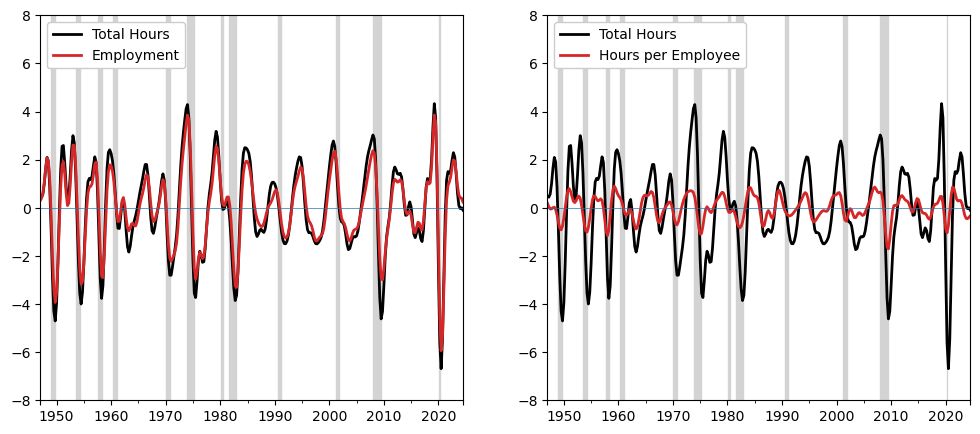

,Total Hours,Employment,Hours per Employee
Total Hours,4.314413,3.579459,0.734932
Employment,3.579459,3.113254,0.466225
Hours per Employee,0.734932,0.466225,0.268664


In [6]:
hp_cycle.columns = ['Output','Total Hours','Hours per Employee','Employment']
cf_cycle.columns = ['Output','Total Hours','Hours per Employee','Employment']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))

cf_cycle[['Total Hours','Employment']].to_period('D').plot(ax=ax1, style=['k-','C3-'], lw=2)

ax1.set_ylim(-8, 8)
ylim = ax1.get_ylim()

ax1.hlines(0, cf_cycle.index[0], cf_cycle.index[-1], linewidth=0.5)
ax1.fill_between(fred.index, ylim[0], ylim[1], fred['USREC'], facecolor='lightgrey', edgecolor='lightgrey')

l = ax1.legend(loc='upper left') #, fontsize=12
# l.get_frame().set_linewidth(0)
l.get_frame().set_alpha(1)

ax1.set_xlabel('')

cf_cycle[['Total Hours','Hours per Employee']].to_period('D').plot(ax=ax2, style=['k-','C3-'], lw=2)

ax2.set_ylim(-8, 8)
ylim = ax2.get_ylim()

ax2.hlines(0, cf_cycle.index[0], cf_cycle.index[-1], linewidth=0.5)
ax2.fill_between(fred.index, ylim[0], ylim[1], fred['USREC'], facecolor='lightgrey', edgecolor='lightgrey')

l = ax2.legend(loc='upper left') #, fontsize=12
# l.get_frame().set_linewidth(0)
l.get_frame().set_alpha(1)

ax2.set_xlabel('')

# ax1.legend()
# ax2.legend()

# plt.title('Deviations from Christiano-Fitzgerald trend')
plt.savefig('Hours_CF.pdf', bbox_inches='tight', pad_inches=0.05)
plt.show()

hp_cycle[['Total Hours','Employment','Hours per Employee']].cov()

In [7]:
dta = fred.copy()
dta.tail()

,USREC,CLF16OV,UNEMPLOY,UNRATE,JTSJOL,JTSJOR
DATE,,,,,,
2024-07-01,0,168429.0,7163.0,4.3,7711.0,4.6
2024-08-01,0,168549.0,7115.0,4.2,7861.0,4.7
2024-09-01,0,168699.0,6834.0,4.1,7372.0,4.4
2024-10-01,0,168479.0,6984.0,4.1,7744.0,4.6
2024-11-01,0,168286.0,7145.0,4.2,NaN,NaN


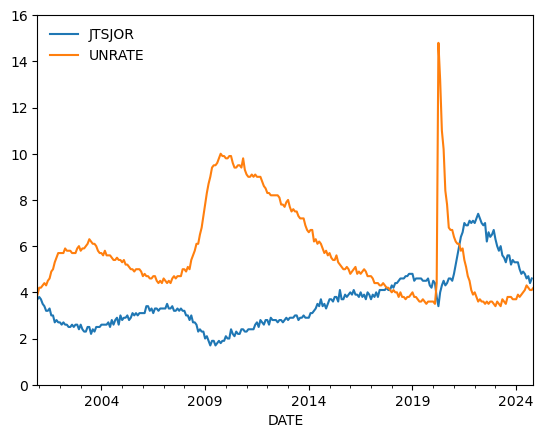

In [8]:
dta[['JTSJOR','UNRATE']]['2000-12':].plot()
plt.legend(frameon=False)
plt.show()

In [ ]:
# Read in Regis Barnichon's Composite Help Wanted Index
hwi = pd.read_csv('Dane/HWI_index_old.txt', delimiter='\t', skiprows=5)

# Manage dates
dates = []
for date in hwi['Date ']:
    dates.append(date[-2:]+'-01-'+date[0:4])

hwi.index = pd.to_datetime(dates)
hwi.index.rename('DATE', inplace=True)

# Cleanup
hwi = hwi.drop('Date ', 1)
hwi.columns = ['HWI']
hwi.tail()

C:\Users\Marcin\AppData\Local\Temp\ipykernel_12096\4214066755.py:13: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  hwi = hwi.drop('Date ', 1)


,HWI
DATE,
2014-08-01,92.02
2014-09-01,87.76
2014-10-01,90.36
2014-11-01,91.35
2014-12-01,89.19


In [10]:
df = dta.join(hwi)

df.head()

,USREC,CLF16OV,UNEMPLOY,UNRATE,JTSJOL,JTSJOR,HWI
DATE,,,,,,,
1947-01-01,0,NaN,NaN,NaN,NaN,NaN,NaN
1947-02-01,0,NaN,NaN,NaN,NaN,NaN,NaN
1947-03-01,0,NaN,NaN,NaN,NaN,NaN,NaN
1947-04-01,0,NaN,NaN,NaN,NaN,NaN,NaN
1947-05-01,0,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df.tail()

,USREC,CLF16OV,UNEMPLOY,UNRATE,JTSJOL,JTSJOR,HWI
DATE,,,,,,,
2024-07-01,0,168429.0,7163.0,4.3,7711.0,4.6,NaN
2024-08-01,0,168549.0,7115.0,4.2,7861.0,4.7,NaN
2024-09-01,0,168699.0,6834.0,4.1,7372.0,4.4,NaN
2024-10-01,0,168479.0,6984.0,4.1,7744.0,4.6,NaN
2024-11-01,0,168286.0,7145.0,4.2,NaN,NaN,NaN


C:\Users\Marcin\AppData\Local\Temp\ipykernel_12096\3145900900.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Vacancies']['2005-01-01':] = df['JTSJOL']['2005-01-01':]


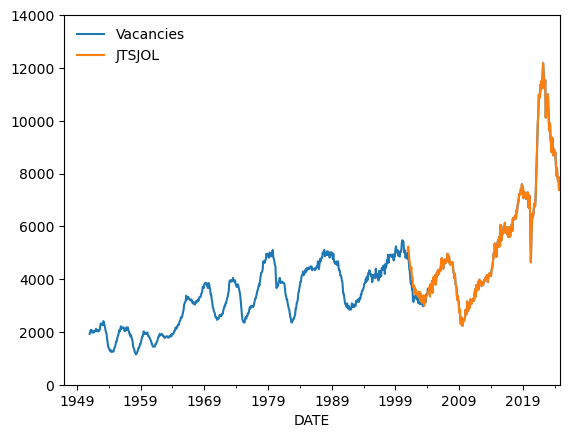

In [12]:
df['Vacancies'] = df['JTSJOL']['2014-01-01'] * df['HWI'] / df['HWI']['2014-01-01']
df['Vacancies']['2005-01-01':] = df['JTSJOL']['2005-01-01':]

df[['Vacancies','JTSJOL']].plot()
plt.legend(frameon=False)
plt.show()

In [13]:
df['Unemployment rate'] = 100 * df['UNEMPLOY'] / df['CLF16OV']
df['Vacancy rate'] = 100 * df['Vacancies'] / df['CLF16OV']

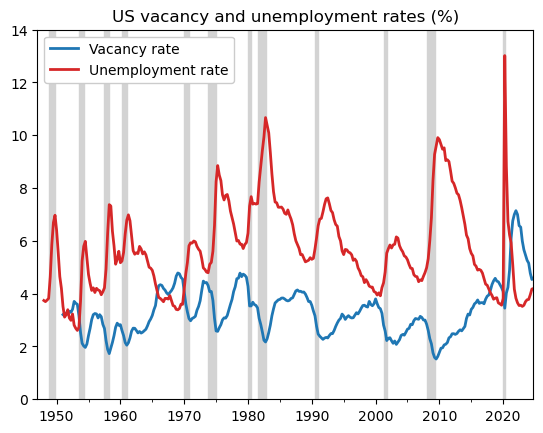

In [14]:
fig, ax = plt.subplots()

df['Vacancy rate'].resample('QS').mean().plot(ax=ax, lw=2) #, style='k'
df['Unemployment rate'].resample('QS').mean().plot(ax=ax, style='C3', lw=2) #
# ((df['Vacancy rate']*df['Unemployment rate'])**(1/2)).resample('QS').mean().plot(ax=ax, lw=2)

ax.set_ylim(0, 14)
ylim = ax.get_ylim()

ax.fill_between(fred.index, ylim[0], ylim[1], fred['USREC'], facecolor='lightgrey', edgecolor='lightgrey')

l = ax.legend(loc='upper left') #, fontsize=12
# l.get_frame().set_linewidth(0)
l.get_frame().set_alpha(1)

plt.xlabel('')

plt.title('US vacancy and unemployment rates (%)')
plt.savefig('VU.pdf')
plt.show()

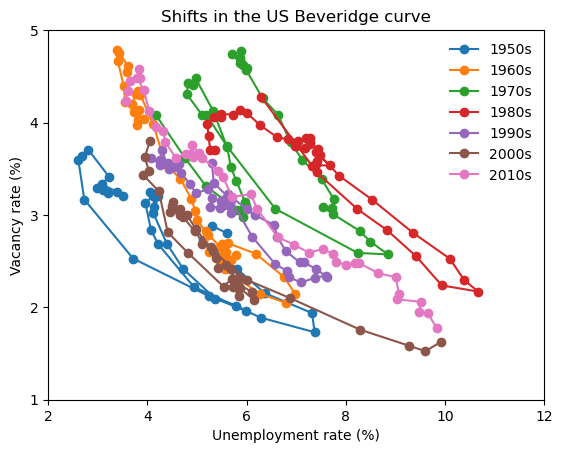

In [15]:
dfq = df.resample('QS').mean()

# plt.plot(dfq['Unemployment rate'], dfq['Vacancy rate'], 'o-')

plt.plot(dfq['Unemployment rate']['1950-01-01':'1959-12-01'], 
         dfq['Vacancy rate']['1950-01-01':'1959-12-01'], 'o-', label='1950s')
plt.plot(dfq['Unemployment rate']['1960-01-01':'1969-12-01'], 
         dfq['Vacancy rate']['1960-01-01':'1969-12-01'], 'o-', label='1960s')
plt.plot(dfq['Unemployment rate']['1970-01-01':'1979-12-01'], 
         dfq['Vacancy rate']['1970-01-01':'1979-12-01'], 'o-', label='1970s')
plt.plot(dfq['Unemployment rate']['1980-01-01':'1989-12-01'], 
         dfq['Vacancy rate']['1980-01-01':'1989-12-01'], 'o-', label='1980s')
plt.plot(dfq['Unemployment rate']['1990-01-01':'1999-12-01'], 
         dfq['Vacancy rate']['1990-01-01':'1999-12-01'], 'o-', label='1990s')
plt.plot(dfq['Unemployment rate']['2000-01-01':'2009-12-01'], 
         dfq['Vacancy rate']['2000-01-01':'2009-12-01'], 'o-', label='2000s')
plt.plot(dfq['Unemployment rate']['2010-01-01':'2019-12-01'], 
         dfq['Vacancy rate']['2010-01-01':'2019-12-01'], 'o-', label='2010s')
# plt.plot(dfq['Unemployment rate']['2020-01-01':], 
#          dfq['Vacancy rate']['2020-01-01':], 'o-', label='2020s')

plt.legend(frameon=False)
plt.xlim(2, 12)
plt.ylim(1, 5)
plt.yticks(np.arange(1, 6))

plt.xlabel('Unemployment rate (%)')
plt.ylabel('Vacancy rate (%)')

plt.title('Shifts in the US Beveridge curve')
plt.savefig('BC.pdf')
plt.show()

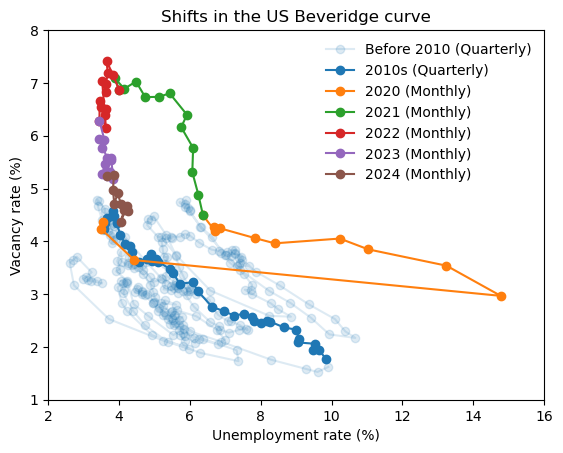

In [16]:
dfq = df.resample('QS').mean()

# plt.plot(dfq['Unemployment rate'], dfq['Vacancy rate'], 'o-')

plt.plot(dfq['Unemployment rate']['1945-01-01':'2009-12-01'], 
         dfq['Vacancy rate']['1945-01-01':'2009-12-01'], 'o-', color='C0', alpha=0.15, label='Before 2010 (Quarterly)')
plt.plot(dfq['Unemployment rate']['2010-01-01':'2019-12-01'], 
         dfq['Vacancy rate']['2010-01-01':'2019-12-01'], 'o-', label='2010s (Quarterly)')
plt.plot(df['Unemployment rate']['2020-01-01':'2021-01-01'], 
         df['Vacancy rate']['2020-01-01':'2021-01-01'], 'o-', label='2020 (Monthly)')
plt.plot(df['Unemployment rate']['2021-01-01':'2022-01-01'], 
         df['Vacancy rate']['2021-01-01':'2022-01-01'], 'o-', label='2021 (Monthly)')
plt.plot(df['Unemployment rate']['2022-01-01':'2023-01-01'], 
         df['Vacancy rate']['2022-01-01':'2023-01-01'], 'o-', label='2022 (Monthly)')
plt.plot(df['Unemployment rate']['2023-01-01':'2024-01-01'], 
         df['Vacancy rate']['2023-01-01':'2024-01-01'], 'o-', label='2023 (Monthly)')
plt.plot(df['Unemployment rate']['2024-01-01':], 
         df['Vacancy rate']['2024-01-01':], 'o-', label='2024 (Monthly)')

plt.legend(frameon=False)
# plt.xlim(2, 12)
# plt.ylim(1, 5)
# plt.yticks(np.arange(1, 6))

plt.xlabel('Unemployment rate (%)')
plt.ylabel('Vacancy rate (%)')

plt.title('Shifts in the US Beveridge curve')
plt.savefig('BC_2020.pdf')
plt.show()

In [17]:
hp_cycle_uv = pd.DataFrame()
hp_trend_uv = pd.DataFrame()
cf_cycle_uv = pd.DataFrame()
cf_trend_uv = pd.DataFrame()


for col in df[['Vacancy rate','Unemployment rate']].columns:
    hp_cycle_uv[col], hp_trend_uv[col] = sm.tsa.filters.hpfilter(100*np.log(df[col][:'2020-01-01']).dropna(), lamb=1600*3**4)
    cf_cycle_uv[col], cf_trend_uv[col] = sm.tsa.filters.cffilter(100*np.log(df[col][:'2020-01-01']).dropna(), low=1.5*12, high=8*12)
    # hp_cycle_uv[col], hp_trend_uv[col] = sm.tsa.filters.hpfilter(100*np.log(df[col]).dropna(), lamb=1600*3**4)
    # cf_cycle_uv[col], cf_trend_uv[col] = sm.tsa.filters.cffilter(100*np.log(df[col]).dropna(), low=1.5*12, high=8*12)

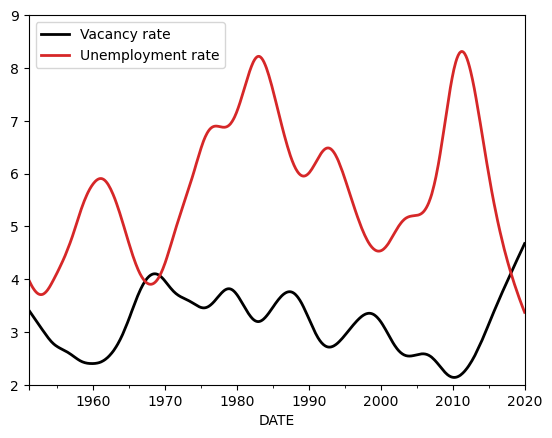

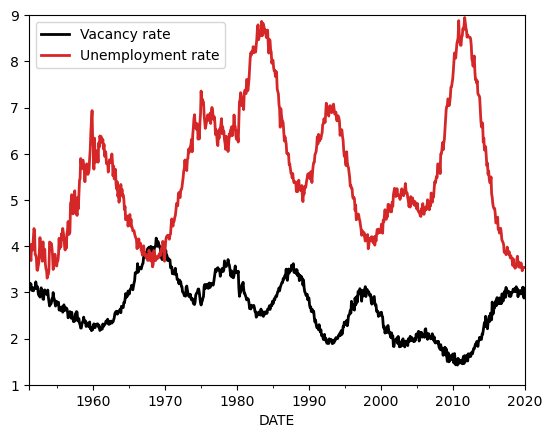

In [18]:
np.exp(hp_trend_uv/100).to_period('D').plot(style=['k','C3'], lw=2)
plt.show()

np.exp(cf_trend_uv/100).to_period('D').plot(style=['k','C3'], lw=2)
plt.show()

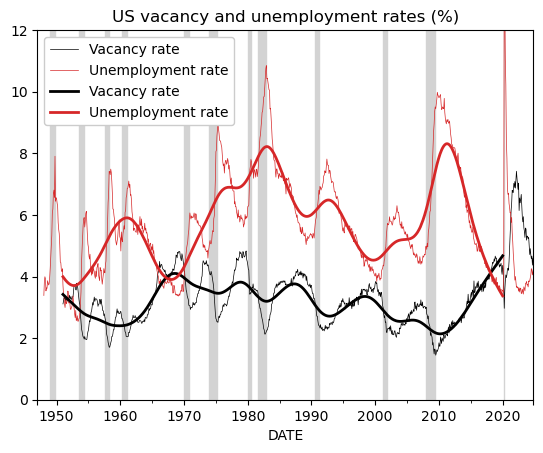

In [19]:
fig, ax = plt.subplots()

df['Vacancy rate'].to_period('D').plot(ax=ax, style='k', lw=0.5) #.resample('QS').mean()
df['Unemployment rate'].to_period('D').plot(ax=ax, style='C3', lw=0.5) #.resample('QS').mean()
np.exp(hp_trend_uv/100).to_period('D').plot(ax=ax, style=['k','C3'], lw=2)

ax.set_ylim(0, 12)
ylim = ax.get_ylim()

ax.fill_between(fred.index, ylim[0], ylim[1], fred['USREC'], facecolor='lightgrey', edgecolor='lightgrey')

l = ax.legend(loc='upper left') #, fontsize=12
# l.get_frame().set_linewidth(0)
l.get_frame().set_alpha(1)

# plt.legend()

plt.title('US vacancy and unemployment rates (%)')
# plt.savefig('VU.pdf')
plt.show()

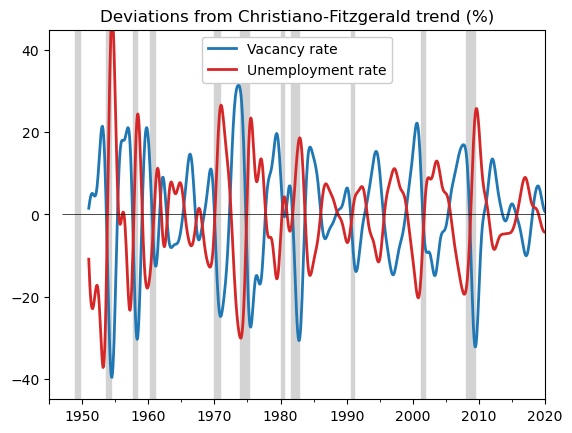

In [20]:
fig, ax = plt.subplots()

cf_cycle_uv.to_period('D').plot(ax=ax, style=['C0','C3'], lw=2) #.resample('QS').mean()
# cf_cycle['Output'].plot(ax=ax, style=['b'], lw=2)

ax.set_ylim(-45, 45)
ylim = ax.get_ylim()

ax.hlines(0, hours[:'2020-01-01'].index[0], hours[:'2020-01-01'].index[-1], color='k', linewidth=0.5)

ax.fill_between(fred[:'2020-01-01'].index, ylim[0], ylim[1], fred['USREC'][:'2020-01-01'], facecolor='lightgrey', edgecolor='lightgrey')

ax.set_xlim('1945-01', hours[:'2020-01-01'].index[-1])

# ax.hlines(0, hours.index[0], hours.index[-1], color='k', linewidth=0.5)

# ax.fill_between(fred.index, ylim[0], ylim[1], fred['USREC'], facecolor='lightgrey', edgecolor='lightgrey')

# ax.set_xlim('1945-01', hours.index[-1])

l = ax.legend(loc='upper center') #, fontsize=12
# l.get_frame().set_linewidth(0)
l.get_frame().set_alpha(1)

plt.xlabel('')

plt.title('Deviations from Christiano-Fitzgerald trend (%)')
plt.savefig('VU_CF.pdf')
plt.show()

-0.923432192198551
-0.4280042990851128
[[ 1.         -0.87796472]
 [-0.87796472  1.        ]]


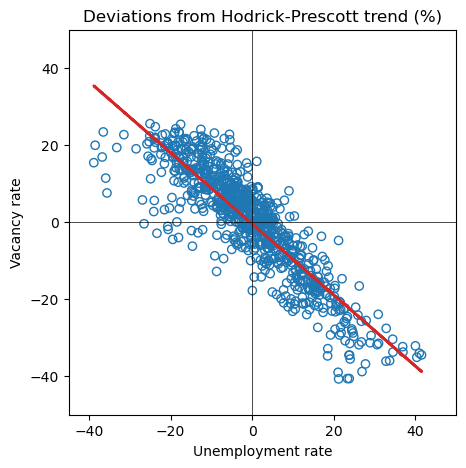

In [21]:
x = hp_cycle_uv['Unemployment rate'] #.resample('QS').mean()
y = hp_cycle_uv['Vacancy rate'] #.resample('QS').mean()

slope, intercept = np.polyfit(x, y, 1)

print(slope)
print(intercept)
print(np.corrcoef(x, y))

fig, ax = plt.subplots(figsize=(5, 5))

# plt.scatter(x, y, alpha=0.3) #, color='k'
plt.scatter(x, y, facecolor='none', edgecolor='C0')
# plt.plot(x, -x, 'r-', lw=2)
plt.plot(x, intercept + slope*x, 'C3-', lw=2)	#, alpha=0.5
# plt.plot(x, -x, 'C3-', lw=2)

plt.xlim(-45, 50)
plt.ylim(-50, 50)

plt.hlines(0, -50, 50, color='k', linewidth=0.5)
plt.vlines(0, -50, 50, color='k', linewidth=0.5)

plt.title('Deviations from Hodrick-Prescott trend (%)')
plt.xlabel('Unemployment rate')
plt.ylabel('Vacancy rate')

# plt.savefig('BC_HP.pdf')

plt.show()

5.683808233862711 3.342700693992768


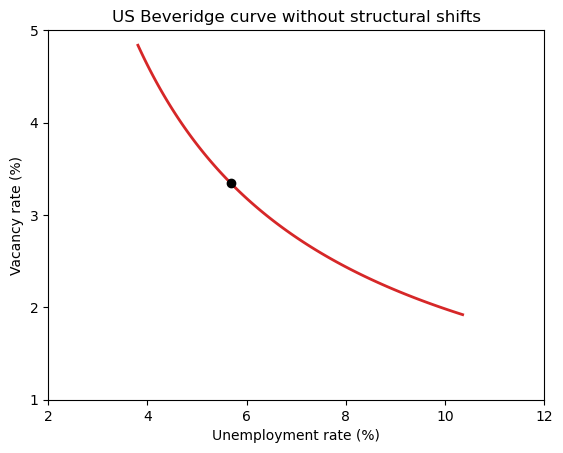

In [22]:
u = np.mean(dfq['Unemployment rate'])
v = np.mean(dfq['Vacancy rate'])

print(u, v)

scale = np.linspace(-40, 60, 101)

plt.plot(u*np.exp(scale/100), v*np.exp(slope*scale/100), 'C3', lw=2)

plt.plot(u, v, 'ko')

plt.xlim(2, 12)
plt.ylim(1, 5)
plt.yticks(np.arange(1, 6))

plt.xlabel('Unemployment rate (%)')
plt.ylabel('Vacancy rate (%)')
plt.title('US Beveridge curve without structural shifts')

plt.savefig('BC_est.pdf')

plt.show()

5.683808233862711 3.342700693992768


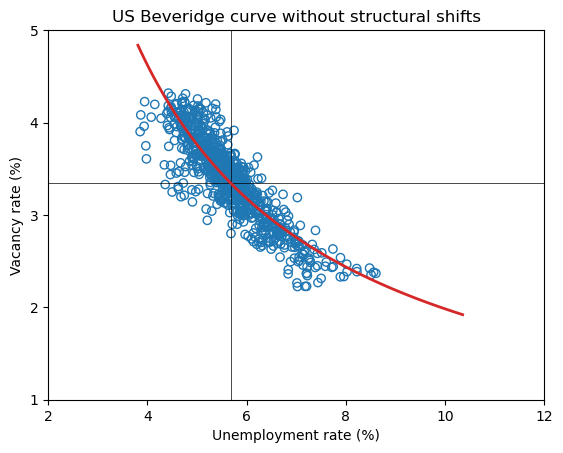

In [23]:
u = np.mean(dfq['Unemployment rate'])
v = np.mean(dfq['Vacancy rate'])

print(u, v)

scale = np.linspace(-40, 60, 101)

fig, ax = plt.subplots()

ax.hlines(v, 2, 12, 'k', linewidth=0.5)
ax.vlines(u, 1, 5, 'k', linewidth=0.5)

plt.plot(u*np.exp(scale/100), v*np.exp(slope*scale/100), 'C3', lw=2)
plt.scatter(u*np.exp(x/100), v*np.exp(y/100), marker='o', facecolor='none', edgecolor='C0')		# marker='.'

plt.xlim(2, 12)
plt.ylim(1, 5)
plt.yticks(np.arange(1, 6))

plt.xlabel('Unemployment rate (%)')
plt.ylabel('Vacancy rate (%)')
plt.title('US Beveridge curve without structural shifts')

plt.savefig('BC_est_2.pdf')

plt.show()

In [24]:
matching = DataReader(['UNEMPLOY', 'JTSJOL', 'JTSHIL', 'JTSQUL'], 'fred', start=start, end=end)

In [25]:
matching['ln(V/U)'] = np.log(matching['JTSJOL'] / matching['UNEMPLOY'])
matching['ln(f)'] = np.log((matching['JTSHIL'] - matching['JTSQUL']) / matching['UNEMPLOY'])

# matching['log(V/U)'] = (matching['JTSJOL'] / matching['UNEMPLOY'])
# matching['log(p)'] = ((matching['JTSHIL'] - matching['JTSQUL']) / matching['UNEMPLOY'])

In [26]:
# x = matching['log(V/U)']['2010-01-01':'2019-12-01'].dropna()
# y = matching['log(p)']['2010-01-01':'2019-12-01'].dropna()

# plt.scatter(x, y)

# slope, intercept = np.polyfit(x, y, deg=1)
# plt.plot(x, intercept + slope*x, 'C3-', lw=2)	#, alpha=0.5

# print(slope)
# print(intercept)
# print(np.corrcoef(x, y))

# plt.show()

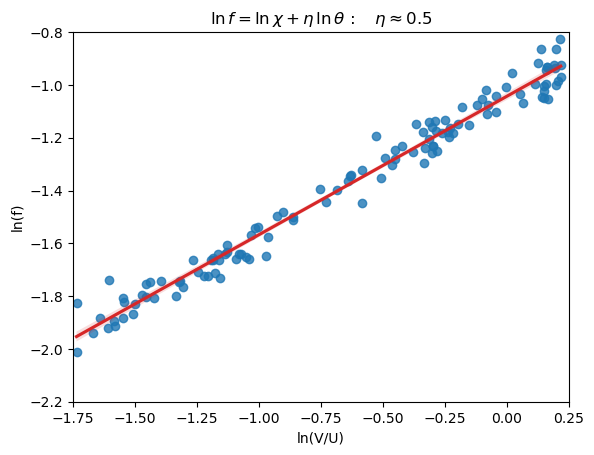

slope 0.5245922201622527


In [27]:
import seaborn as sns
import scipy.stats as sps

x = matching['ln(V/U)']['2010-01-01':'2019-12-01'].dropna()
y = matching['ln(f)']['2010-01-01':'2019-12-01'].dropna()

sns.regplot(x=x, y=y, line_kws=dict(color='C3'))

# plt.title(r'$\eta \approx 0.5$')
plt.title(r'$\ln f = \ln \chi + \eta \, \ln \theta \, : \quad \eta \approx 0.5$')

plt.savefig('Match_est.pdf')

plt.show()

linreg = sps.linregress(x, y)

# print(linreg)
print('slope', linreg.slope)

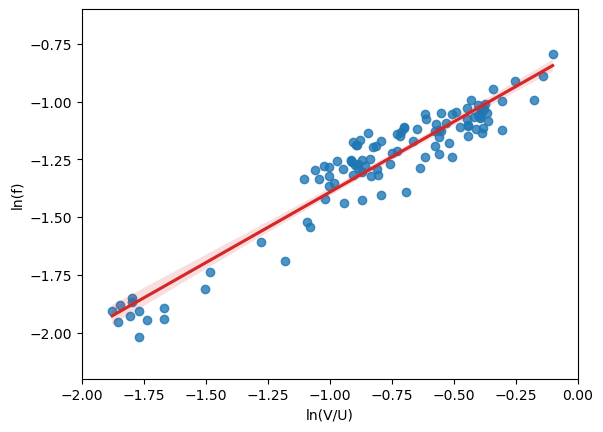

slope 0.6099205926243078


In [28]:
x = matching['ln(V/U)'][:'2010-01-01'].dropna()
y = matching['ln(f)'][:'2010-01-01'].dropna()

sns.regplot(x=x, y=y, line_kws=dict(color='C3'))

plt.show()

linreg = sps.linregress(x, y)

# print(linreg)
print('slope', linreg.slope)

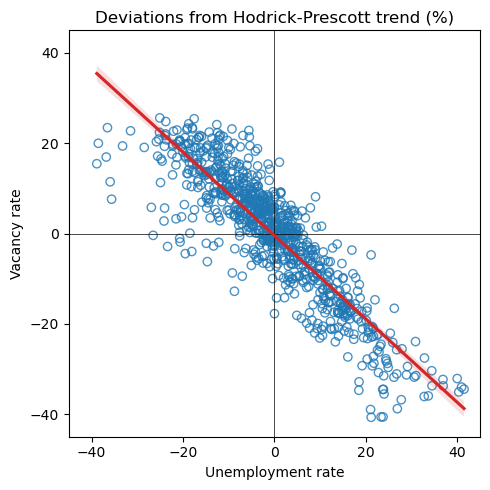

slope -0.9234321921985511


In [37]:
x = hp_cycle_uv['Unemployment rate'] #.resample('QS').mean()
y = hp_cycle_uv['Vacancy rate'] #.resample('QS').mean()

fig, ax = plt.subplots(figsize=(5, 5))

ax.hlines(0, -45, 45, color='k', lw=0.5)
ax.vlines(0, -45, 45, color='k', lw=0.5)

sns.regplot(ax=ax, x=x, y=y, line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))

plt.xlim(-45, 45)
plt.ylim(-45, 45)

plt.title('Deviations from Hodrick-Prescott trend (%)')
plt.xlabel('Unemployment rate')
plt.ylabel('Vacancy rate')

plt.tight_layout()
plt.savefig('BC_HP.pdf')
plt.show()


linreg = sps.linregress(x, y)
print('slope', linreg.slope)

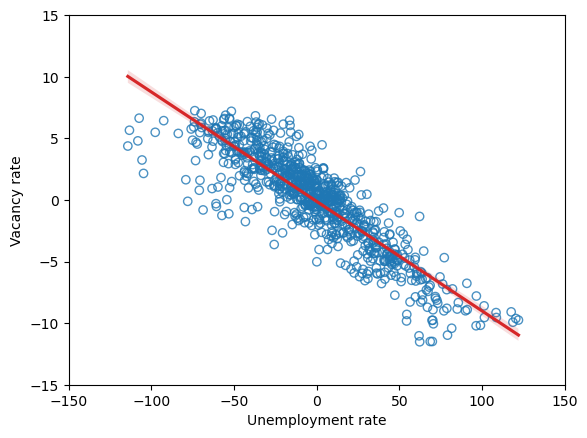

In [60]:
u = np.mean(dfq['Unemployment rate'])
v = np.mean(dfq['Vacancy rate'])

fig, ax = plt.subplots()

sns.regplot(ax=ax, x=x/100*np.exp(u), y=y/100*np.exp(v), line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))

# ax.set_yscale('exp')
# ax.set_xscale('log')

plt.show()

In [67]:
# u = np.mean(dfq['Unemployment rate'])
# v = np.mean(dfq['Vacancy rate'])

# print(u, v)

# scale = np.linspace(-40, 60, 101)

# fig, ax = plt.subplots()

# ax.hlines(v, 2, 12, 'k', linewidth=0.5)
# ax.vlines(u, 1, 5, 'k', linewidth=0.5)

# # sns.regplot(ax=ax, x=u*np.exp(x/100), y=y/100, logx=True, line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))
# # sns.regplot(ax=ax, x=u*np.exp(x/100), y=v*np.exp(y/100), logx=True, line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))
# # sns.regplot(ax=ax, x=u*np.exp(x/100), y=v*np.exp(y/100), order=2, line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))

# # ax.set_yscale('log')

# plt.plot(u*np.exp(scale/100), v*np.exp(slope*scale/100), 'C3', lw=2)
# plt.scatter(u*np.exp(x/100), v*np.exp(y/100), marker='o', facecolor='none', edgecolor='C0')		# marker='.'

# # plt.xlim(2, 12)
# # plt.ylim(1, 5)
# # plt.yticks(np.arange(1, 6))

# plt.xlabel('Unemployment rate (%)')
# plt.ylabel('Vacancy rate (%)')
# plt.title('US Beveridge curve without structural shifts')

# # plt.savefig('BC_est_2.pdf')

# plt.show()

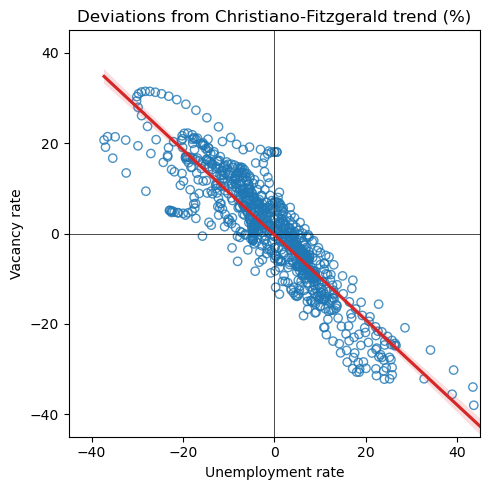

slope -0.9418114104490942


In [30]:
x = cf_cycle_uv['Unemployment rate'] #.resample('QS').mean()
y = cf_cycle_uv['Vacancy rate'] #.resample('QS').mean()

fig, ax = plt.subplots(figsize=(5, 5))

ax.hlines(0, -45, 45, color='k', lw=0.5)
ax.vlines(0, -45, 45, color='k', lw=0.5)

sns.regplot(ax=ax, x=x, y=y, line_kws=dict(color='C3'), scatter_kws=dict(facecolor='none'))

plt.xlim(-45, 45)
plt.ylim(-45, 45)

plt.title('Deviations from Christiano-Fitzgerald trend (%)')
plt.xlabel('Unemployment rate')
plt.ylabel('Vacancy rate')

plt.tight_layout()
plt.savefig('BC_CF.pdf')
plt.show()


linreg = sps.linregress(x, y)
print('slope', linreg.slope)